# 5TF078 Deep Learning Course
## Excercise 2 Transfer Learning on Fashion-MNIST
Created by Tomas Nordström, Umeå University

### Revisions:

* 2022-04-01 First revision based on earlier excercises /ToNo
* 2025-04-27 Added AI-declaration. /Tomas
* 2025-11-19 Info about that Xception want its RGB range to be –1.0 to 1.0 (VG part). Better indication for student code and analysis in part B. /Tomas

## AKINYI M OCHOLLA. Version 2

# First we initilize our Python environment

In [30]:
#### Set up tests to know if we are running Colab or Kaggle
import sys

### Is this notebook running on Colab?
IS_COLAB = "google.colab" in sys.modules

### Is this notebook running on Kaggle?
# Fool Kaggle into making kaggle_secrets avaiable
try:
    import kaggle_secrets
except ImportError as e:
    pass
# Now we can test for Kaggle
IS_KAGGLE = "kaggle_secrets" in sys.modules

In [ ]:
# Set up Keras/Tensorflow framework
import os
os.environ["KERAS_BACKEND"] = "tensorflow" # Also tensorflow, jax, pytorch for Keras 3.0

import keras
print('Keras version:', keras.__version__)

# Import needed libraries
import tensorflow as tf
print('TensorFlow version:', tf.__version__)

In [32]:
#### Additional helper libraries
import pandas as pd
import numpy as np
import time
import sklearn
import tensorflow_datasets as tfds

# Matlab plotting
import matplotlib
import matplotlib.pyplot as plt

In [33]:
# Test for GPU and determine what GPU we have
import platform
import subprocess
gpu_devices = tf.config.list_physical_devices('GPU')

gpu_name = tf.test.gpu_device_name()
if gpu_name != '':
    print('TF-GPU-devname:',tf.test.gpu_device_name())
    sys_details = tf.sysconfig.get_build_info()
    physical_devices = tf.config.list_physical_devices('GPU')
    print("Num GPUs:", len(physical_devices))
    if platform.system() == "Darwin":
        print('GPU on Mac!')
    else:
        cuda_version = sys_details["cuda_version"]
        print('TF-cuda version:',cuda_version)
        if len(physical_devices)>0:
            process = subprocess.Popen(['nvidia-smi','-L'], stdout=subprocess.PIPE, stderr=subprocess.PIPE)
            print(process.communicate())
        # If possible to run code with 16 bits float instead of 32 bits float, this code activates such functionality:
        if gpu_devices:
            details = tf.config.experimental.get_device_details(gpu_devices[0])
            compute_capability=details.get('compute_capability')
            print("Compute capability:",compute_capability)
            if compute_capability[0]>6:
                print("Turning on mixed_float16")
                policy = keras.mixed_precision.Policy('mixed_float16')
                keras.mixed_precision.set_global_policy(policy)
else:
    print('TF-device CPU')

TF-GPU-devname: /device:GPU:0
Num GPUs: 1
TF-cuda version: 12.5.1
(b'GPU 0: Tesla P100-PCIE-16GB (UUID: GPU-c6a16933-7b6a-544e-d806-054966938c16)\n', b'')
Compute capability: (6, 0)


I0000 00:00:1764000949.567085      48 gpu_device.cc:2022] Created device /device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1764000949.568090      48 gpu_device.cc:2022] Created device /device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


# Set up the needed data sets, its preprocessing, and making it into a stream.

## Get hold of a data-set
In this exercise we will use Fashion MNIST dataset, which an alternative to MNIST (it is a little harder, but the image size is the same). This is available directly as a [Keras dataset](https://keras.io/datasets/). This is a dataset of 60,000 28x28 grayscale images of 10 fashion categories, along with a test set of 10,000 images.

Note that we split our data into **three** data sets: training, validation, testing; each with its own purpose.

In [34]:
#### Get Fashion-MNIST info of data with tfds 
#dataset, info = tfds.load("fashion_mnist", as_supervised=True, with_info=True)

In [35]:
#fig = tfds.show_examples(dataset, info)

In [36]:
#### Get Fashion-MNIST training and test data from Keras database (https://keras.io/datasets/)
(train_images0, train_labels0), (test_images, test_labels) = keras.datasets.fashion_mnist.load_data()

# Define labels
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
num_classes = len(class_names)

# Normalise images to a float between 0 and 1
train_images0 = train_images0.astype('float32') / 255
test_images = test_images.astype('float32') / 255

# Add empty color dimensions to images
train_images0 = np.expand_dims(train_images0, -1)
test_images = np.expand_dims(test_images, -1)

Note that the training labels are an integer between 0 and 9, which is not very good as outputs (or inputs) for DL models. A better approach will be to use a one-hot encoding. We can convert our label vectors to one-hot encoded matrices by using [to_categorical](https://www.tensorflow.org/api_docs/python/tf/keras/utils/to_categorical) `keras.utils.to_categorical(train_labels)`. This was used in Excercise 1.

In this Excercise we will achieve the same thing by using [SparseCategoricalCrossentropy](https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class) as a loss function instead of the [CategoricalCrossentropy](https://keras.io/api/losses/probabilistic_losses/#categoricalcrossentropy-class). But note that for both cases we need our model to have as many output nodes as we have classes!

## Set up the streaming of data

### STUDENTSVAR (Kod):

In [37]:
### Hur färgen är kodad som RGB eller BGR ser vi genom att kolla channel statistics av bilderna. Oftast sägs det att om den sista pixeln i en image är större än den första d.v.s 3 så anses bilden vara i RGB-format, medans 
### om den första pixeln i bilden är större än den sista så är bilden i BGR-format
### https://codingtechroom.com/question/how-to-determine-image-rgb-bgr-format

In [111]:
#### Function to reformat data so that we can use a predefined network
### Den minsta hanterbar vidgen och höjden av en VGG16 bild är 32. Därför har vi här nedan dublerat MNIST bilden.

# Later you will find out what is the minumum size
##################### TODO: MIGHT NEED AN UPDATE #####################
NEWIMG_WIDTH = 28*3
NEWIMG_HEIGHT = 28*3

# Define an in-stream transform function (normalize, add color-dim, gray2color, resize)
def ds_img_transform(images,labels):
    ##################### TODO: YOUR CODE STARTS HERE #####################
   images = tf.image.grayscale_to_rgb(tf.convert_to_tensor(images))
   images = tf.image.resize_with_pad(images, NEWIMG_WIDTH, NEWIMG_HEIGHT, antialias=False)
    ##################### TODO: YOUR CODE ENDS HERE #######################
   return images,labels

In [112]:
#### Get the three datasets (train, validation and test) from our data
##################### TODO: CAN BE CHANGED #####################
batch_size = 352

# split training into training and validation
train_ds,val_ds = keras.utils.split_dataset((train_images0, train_labels0), right_size=0.2)
test_ds = tf.data.Dataset.from_tensor_slices((test_images, test_labels))

# https://www.tensorflow.org/guide/data_performance
# Apply image mapping and set up batching of our datasets
train_ds = train_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
val_ds   =   val_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
test_ds  =  test_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True)

## Explore the data
It is always advised to take a look at the data, especially after applying various modifications like in ds_img_transform above. But now the data is in datasets and we need to grab a batch by using `dataset.take()`

In [113]:
for ex_images, ex_labels in test_ds.take(1):  # Take just one batch
    break  # We've extracted what we need

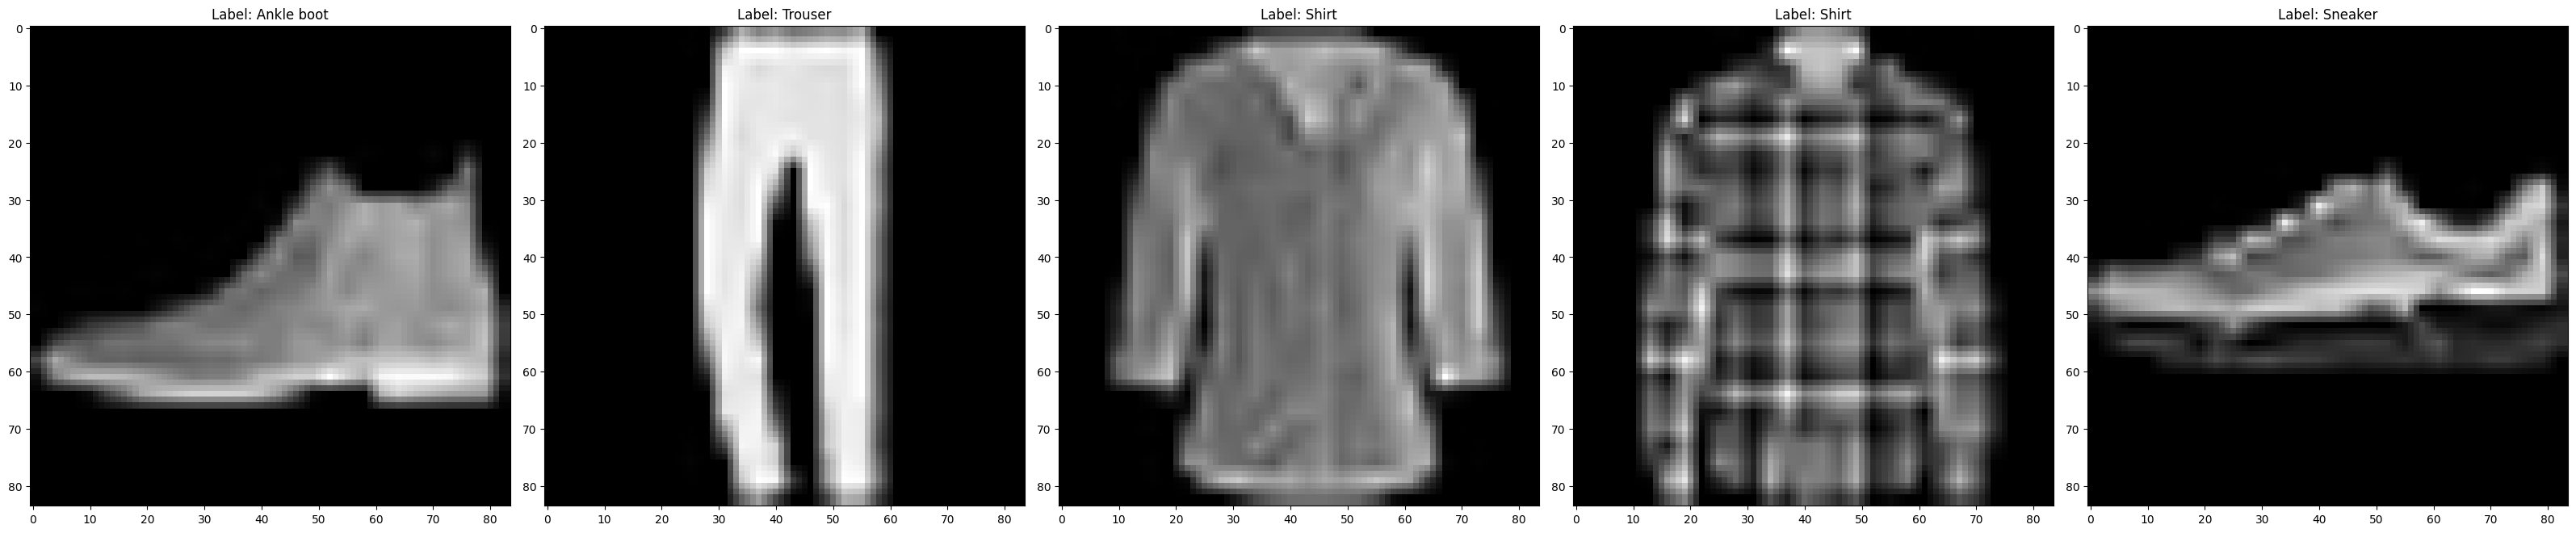

In [114]:
#### Print a few of the test data images

# Index of the images to plot (within the batch)
iix = [0,2,4,7,9]

#plt.figure(figsize=(8, 8))  # Set a larger figure size
plt.figure(figsize=(32, 32))

for i,ix in enumerate(iix):
    # Plot images
    plt.subplot(1,len(iix), i+1)
    plt.imshow(ex_images[ix])
    plt.title(f"Label: {class_names[ex_labels[ix]]}")

plt.tight_layout()
plt.show()

In [115]:
ex_images[0].shape  # Shows the shape of the image 56 x 56 and has three colours 

TensorShape([84, 84, 3])

# Transfer learning
Now follows the main topic of this exercise.

## Read in the model to transfer
You can find the available models at [Keras Applications](https://keras.io/api/applications/)

For this excersize you will use [VGG16](https://keras.io/api/applications/vgg/#vgg16-function).

When loading VGG, you must choose the correct values of some of the input parameters:
* weights='imagenet' --- Since we want to use the weights pretrained on the imagenet
* include_top=False --- This is False, we anyway will replace the "top" with our own layers. Note that they call the layers closest to the output the top layers.
* input_shape= **???** --- Set it to the same shape as the pictures have!

### Uppgift
Om du tittar på sidan för [VGG16](https://keras.io/api/applications/vgg/#vgg16-function), vilken är den minsta möjliga bildstorlek?

**STUDENTSVAR:**
### Den minsta möjliga bildstorlek för en VGG16 model är 32.

### STUDENTSVAR (Kod):

In [116]:
# Detta är input_shape som stoppas in i tl_model nedan. Bildstorleken är 56 vilket är större än 32.
ex_images[0].shape # input_shape = ex_images[0].shape

TensorShape([84, 84, 3])

In [124]:

##################### TODO: YOUR CODE STARTS HERE #####################
#### Read in the model to transfer
input_shape = ex_images[0].shape
tl_model = keras.applications.vgg16.VGG16(weights='imagenet',include_top=False, input_shape=input_shape)

# For now we are not training the parameters in the transfered model
tl_model.trainable = True
##################### TODO: YOUR CODE ENDS HERE #######################
tl_model.summary(show_trainable=True, line_length=100)

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                  ┃        Param # ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer_6 (InputLayer)            │ (None, 84, 84, 3)             │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block1_conv1 (Conv2D)                 │ (None, 84, 84, 64)            │          1,792 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block1_conv2 (Conv2D)                 │ (None, 84, 84, 64)            │         36,928 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block1_pool (MaxPooling2D)            │ (None, 42, 42, 64)            │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block2_conv1 (Conv2D)                 │ (None, 42, 42, 128)           │         73,856 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block2_conv2 (Conv2D)                 │ (None, 42, 42, 128)           │        147,584 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block2_pool (MaxPooling2D)            │ (None, 21, 21, 128)           │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block3_conv1 (Conv2D)                 │ (None, 21, 21, 256)           │        295,168 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block3_conv2 (Conv2D)                 │ (None, 21, 21, 256)           │        590,080 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block3_conv3 (Conv2D)                 │ (None, 21, 21, 256)           │        590,080 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block3_pool (MaxPooling2D)            │ (None, 10, 10, 256)           │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block4_conv1 (Conv2D)                 │ (None, 10, 10, 512)           │      1,180,160 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block4_conv2 (Conv2D)                 │ (None, 10, 10, 512)           │      2,359,808 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block4_conv3 (Conv2D)                 │ (None, 10, 10, 512)           │      2,359,808 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block4_pool (MaxPooling2D)            │ (None, 5, 5, 512)             │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block5_conv1 (Conv2D)                 │ (None, 5, 5, 512)             │      2,359,808 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block5_conv2 (Conv2D)                 │ (None, 5, 5, 512)             │      2,359,808 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block5_conv3 (Conv2D)                 │ (None, 5, 5, 512)             │      2,359,808 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block5_pool (MaxPooling2D)            │ (None, 2, 2, 512)  

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

### Uppgift
Hur många parametrar finns i VGG16?

**NEW STUDENTSVAR:**
VGG16 har 14,714,688 params



**Analysera VGG-modellens lager**

Eftersom Fashion MNIST-bilderna är mycket små (28x28 original men inte mycket större efter skalning) kan vi inte effektivt använda hela modellen, eftersom den innehåller så många lager att de senare faltningslagren degenererar. Detta kan observeras i kolumnen Output Shape i model.summary. Där vi ser att lager på slutet får en "bildstorlek" som är av samma storlek som faltningskärnorna.

### Uppgift
Om du tittar på VGGs `model.summary` ovan, vid vilket lager kan det vara lämpligt att stanna? Notera detta kommer att bero på hur mycket du skalat upp inbilden. Det kommer också delvis bero på hur dina egna lager ser ut, som om du t.ex. vill ha ett eget faltningslager eller om du kanske direkt vill platta till modellen och bara köra kompakta lager.)

**STUDENTSVAR:**
###  

In [126]:
##################### TODO: CHANGE!
# I först rundan har bilderna storlek 56x56x3 så jag tror att jag igentligen borde klippa av VGG16 vid lager block1_conv2 (Conv2D). Men, jag vill börja med att se
# hur hela modellen VGG16 funkar med mina Modell-lager.
# name_of_last_TL_layer = 'block1_pool'
# name_of_last_TL_layer = 'block5_pool' # Runda 1 med default layers x = keras.layers.BatchNormalization(axis=-1)(x) och x = keras.layers.Flatten()(x) och batchsize 128
# name_of_last_TL_layer = 'block5_pool'# Runda 2 # Jag la in hela min model inklusivt 4 Conv2D-lager och maxpooling lager och körde med batch size 128 Learning rate 1-e-4-1-e-5
# name_of_last_TL_layer ='block5_pool' # Runda 3 Jag bytte till batch size 352 med 2 conv2d-lager
# name_of_last_TL_layer ='block5_conv3' # Runda 4 Jag behöll 2 conv2D lager, batchsize 352
# name_of_last_TL_layer ='block5_conv2' # Runda 5, behöll 2 conv2d lager, batchsize 352, 
# name_of_last_TL_layer ='block4_conv3' # Runda 6, behöll 2 Conv2d lager, batchsize 352
name_of_last_TL_layer ='block3_pool' #Runda 7, behöll 2 Conv2d lager, batchsize 352


## Build a transfered model

import keras.hyper

In [127]:
#### Build our own layers on top of the transfered model (use a functional definition as this is easier)

# Step 1. Get an output tensor of the last transfer-model layer that we want to include
x = tl_model.get_layer(name_of_last_TL_layer).output

##################### TODO: YOUR CODE STARTS HERE #####################
# Step 2. Stack our own layers on top
# x = keras.layers.BatchNormalization(axis=-1)(x)
##### more layers
# x = keras.layers.Flatten()(x)
##### more layers

#x = keras.layers.MaxPool2D(pool_size=3, strides=2,padding='same')(x) 
#x = keras.layers.Flatten()(x)
#x = keras.layers.Dense(units=32, activation='relu', kernel_initializer='he_normal')(x) 
#x = keras.layers.BatchNormalization()(x)
# x = keras.layers.Conv2D(filters=256, kernel_size=(3, 3), padding='same', activation='relu', kernel_initializer='he_normal')(x) 
x = keras.layers.Conv2D(
        filters=256, 
        kernel_size=(3, 3), 
        padding='same', 
        activation='relu', 
        kernel_initializer='he_normal')(x) 
x = keras.layers.MaxPool2D(pool_size=3, strides=2, padding='same')(x)
# x = keras.layers.Conv2D(filters=256,kernel_size=(3, 3), padding='same', activation='relu', kernel_initializer='he_normal')(x) 
x = keras.layers.Conv2D(
        filters=256, 
        kernel_size=(3, 3), 
        padding='same', 
        activation='relu', 
        kernel_initializer='he_normal')(x) 
x = keras.layers.MaxPool2D(pool_size=3, strides=2,padding='same')(x) 
x = keras.layers.Flatten()(x)
x = keras.layers.Dense(units=32, activation='relu', kernel_initializer='he_normal')(x) 
x = keras.layers.BatchNormalization()(x)
##################### TODO: YOUR CODE ENDS HERE #######################
x = keras.layers.Dense(10, activation='softmax')(x)

# Creating new combined model. Note that this is NOT a Sequential() model.
model = keras.models.Model(inputs=tl_model.input, outputs=x)

print(model.summary(show_trainable=True, line_length=100))

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                  ┃        Param # ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer_6 (InputLayer)            │ (None, 84, 84, 3)             │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block1_conv1 (Conv2D)                 │ (None, 84, 84, 64)            │          1,792 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block1_conv2 (Conv2D)                 │ (None, 84, 84, 64)            │         36,928 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block1_pool (MaxPooling2D)            │ (None, 42, 42, 64)            │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block2_conv1 (Conv2D)                 │ (None, 42, 42, 128)           │         73,856 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block2_conv2 (Conv2D)                 │ (None, 42, 42, 128)           │        147,584 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block2_pool (MaxPooling2D)            │ (None, 21, 21, 128)           │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block3_conv1 (Conv2D)                 │ (None, 21, 21, 256)           │        295,168 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block3_conv2 (Conv2D)                 │ (None, 21, 21, 256)           │        590,080 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block3_conv3 (Conv2D)                 │ (None, 21, 21, 256)           │        590,080 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ block3_pool (MaxPooling2D)            │ (None, 10, 10, 256)           │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ conv2d_18 (Conv2D)                    │ (None, 10, 10, 256)           │        590,080 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ max_pooling2d_18 (MaxPooling2D)       │ (None, 5, 5, 256)             │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ conv2d_19 (Conv2D)                    │ (None, 5, 5, 256)             │        590,080 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ max_pooling2d_19 (MaxPooling2D)       │ (None, 3, 3, 256)             │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ flatten_9 (Flatten)                   │ (None, 2304)                  │              0 │    -    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ dense_18 (Dense)                      │ (None, 32)                    │         73,760 │    Y    │
├───────────────────────────────────────┼───────────────────────────────┼────────────────┼─────────┤
│ batch_normalization_9                 │ (None, 32)                    │            128 │    Y    │
│ (BatchNormalization)                  │                               │                │         │
├───────────────────────────────────────┼────────────────────

 Total params: 2,989,866 (11.41 MB)

 Trainable params: 2,989,802 (11.41 MB)

 Non-trainable params: 64 (256.00 B)

None


### Uppgift
Hur många träningsbara parametrar finns i din överförda modell?
**NEW STUDENTSVAR**
# I default modellen finns 6154 trainable params.
# Runda 2 : Med min model och alla 4 Conv2D lager fick jag trainable params 2,958,762 med batchsize 128
# Runda 3 : Med 2 Conv2D lager av min model i Runda 2 och batch size 352, trainable params 1,778,602.
# Runda 4: Med 2 Conv2D lager av min model i Runda 2, batchsize 352, trainable params 1,778,602
# Runda 5: Med 2 Conv2D lager av min model i Runda 2, batchsize 352, trainable params 1,778,602
# Runda 6: Med 2 Conv2D lager av min model i Runda 2, batchsize 352, trainable params 1,803,178
# Runda 7: Med 2 Conv2D lager av min model i Runda 2, batchsize 352, trainable params 1,213,354


In [128]:
#### Compile the model (note SparseCategoricalCrossentropy as we have not converted labels)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4-1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")]
)

In [ ]:
#### Training the model
# batch_size = 32 # Now set in datastream
epochs = 30

# Set callback functions to early stop training and save the best model so far
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=3,restore_best_weights = True)]

start = time.perf_counter()
history = model.fit(train_ds,
                    epochs=epochs,
                    shuffle=True,
                    verbose=1,
                    validation_data=val_ds,
                    callbacks=callbacks)
end = time.perf_counter()
print(f"Time to run: {end - start:.2f}s",)

In [130]:
# Evaluate
test_loss, test_acc = model.evaluate(test_ds)
print(f'Test accuracy: {test_acc:.3f}')

28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - acc: 0.9438 - loss: 0.1914
Test accuracy: 0.944


## Uppgift
Notera antal parametrar som tränats, testnoggrannhet, körtid
(Notera att en noggrannhet på 91.5% är minimum för denna laboration!)

Vad kan man dra för slutsatser av dina körningar i denna del?

### NEW STUDENTSVAR (Analys):
# Runda 1: Jag använde default klippta modellen och körde med alla lager i VGG16 till block block5_pool. Test noggrannheten blev 0.849
# Runda 2: Jag använde min model med alla Conv2D lager, batchsize 128 och block5_pool. Test noggrannheten blev 0.871
# Runda 3: Jag tog bort två Conv2D lager, och bytte till batchsize 352 och behöll block5_pool. Trainable Params:1,778,602. körtid: 173.23s Test noggrannheten blev 0.870
# Runda 4: Jag behöll bara två Conv2D lager, och batchsize 352 och klippte block5_conv3. Trainable Params:1,778,602. körtid: 135.31s Test noggrannheten blev 0.882
# Runda 5: Jag behöll bara två Conv2D lager, och batchsize 352 och klippte block5_conv2. Trainable Params:1,778,602. körtid:152.43s Test noggrannheten blev 0.901.
# Runda 6: Jag behöll bara två Conv2D lager, och batchsize 352 och klippte block4_conv3. Trainable Params: 1,803,178. körtid:123.44s Test noggrannheten blev 0.919.
# Runda 7: Jag behöll bara två Conv2D lager, och batchsize 352 och klippte block3_pool. trainable params; 1,213,354. körtid:91.25s Test noggrannheten blev 0.927.

# Mina slutsatser är att Det är bättre att börja längst upp i det översta lagret och klippa där och använda så mycket av den pretrained modellen som möjligt och sedan successivt klippa av vid pretränade lager som mer eller mindre liknar mina egna lager i output och shape. Som vi ser här så kom den största test_noggrannheten på 0.919 vid block4_conv3  (None, 7, 7, 512)  som liknar/är en aning större än min Conv2D (None, 7, 7, 256). Också i och med att trainable params blev färre så förkortades träningstiden betydligt till 91.25s från 123.44 i runda 7. I runda 7 har jag uppfyllt minimum 91.5% med 92.7% Alla 7 runder tränade med 28*2 28*2 bildstorlek.




## Uppgift
När du nu funnit de bästa "topplagren" du kan finna, utvärdera din överförda model även med följande variationer:
* bildstorlek: utvärdera med följande bildstorlekar: minimistorlek, 28\*2x28\*2,  28\*3x28\*3.

Notera antal parametrar som tränats, testnoggrannhet, körtid

Vad kan man dra för slutsatser av detta?


### New STUDENTSVAR (Analys):
# Jag ändrade till storlek 28*3 och körde med alla samma trainable params 1,213,354 vid Runda 7.Jag fick en test_noggrannhet av 92.8% och träningstiden tog 264.59s. Det är inte jättestor skillnad från tidigare bildstorlek. 
# Med bildstorlek 32 fick jag test noggrannhet på 92.3% med trainable params 1,188,778. Träningstiden 49.64s. 
# Med storlek 28*4 fick jag trainable params 1,311,658 och test noggrannhet 92.9% men modellen övertränade upp till acc: 1 vid epoch 18-20 och träningstiden tog 429s. Min fundering var främst att det är en viss skillnad mellan 92.3% (width and height 32) och 92.9% (width and height 28*4). Men jag undrar om jag störde modellens inlärning genom att ändra storlek mellan 28*3 ner till 32 och sedan upp till 28*4. Ju flera gånger jag ändrar på höjd och bredd och tränar om modellen desstu mera den verkar överträna och test noggrannheten förblir 92.9%. 



# Del B

För överförd inlärning med VGG enligt ovan så ska du här slå på träning även för några av de importerade lagren och utvärdera hur det påverkar modellens prestanda. Lämpligen slår du först på alla lager för träning: "model.trainable = True". Om du sedan inte vill träna alla lager så kan du loopa över alla lager och göra "layer.trainable = False" där/om så behövs.
Notera att du kan lätt se vilka lager som är träningsbara mha `model.summary(show_trainable=True)`

Notera att du nog bör minska inlärningstakten (till typ 1e-4 -- 1e-5 för Adam) när du även tränar den överförda modellens parametrar, för annars kan den "glömma" för mycket av den förtränade modellen och modellen kan rent av bli sämre.

### STUDENTSVAR (KOD)

In [ ]:
# Kod för del B
"""
#### Function to reformat data so that we can use a predefined network
### Den minsta hanterbar vidgen och höjden av en VGG16 bild är 32. Därför har vi här nedan dublerat MNIST bilden.

# Later you will find out what is the minumum size
##################### TODO: MIGHT NEED AN UPDATE #####################
NEWIMG_WIDTH = 28*3
NEWIMG_HEIGHT = 28*3

# Define an in-stream transform function (normalize, add color-dim, gray2color, resize)
def ds_img_transform(images,labels):
    ##################### TODO: YOUR CODE STARTS HERE #####################
   images = tf.image.grayscale_to_rgb(tf.convert_to_tensor(images))
   images = tf.image.resize_with_pad(images, NEWIMG_WIDTH, NEWIMG_HEIGHT, antialias=False)
    ##################### TODO: YOUR CODE ENDS HERE #######################
   return images,labels
   
##################### TODO: YOUR CODE STARTS HERE #####################
#### Read in the model to transfer
input_shape = ex_images[0].shape
tl_model = keras.applications.vgg16.VGG16(weights='imagenet',include_top=False, input_shape=input_shape)

# For now we are not training the parameters in the transfered model
tl_model.trainable = True
##################### TODO: YOUR CODE ENDS HERE #######################
tl_model.summary(show_trainable=True, line_length=100)

#### Get the three datasets (train, validation and test) from our data
##################### TODO: CAN BE CHANGED #####################
batch_size = 352

# split training into training and validation
train_ds,val_ds = keras.utils.split_dataset((train_images0, train_labels0), right_size=0.2)
test_ds = tf.data.Dataset.from_tensor_slices((test_images, test_labels))

# https://www.tensorflow.org/guide/data_performance
# Apply image mapping and set up batching of our datasets
train_ds = train_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
val_ds   =   val_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
test_ds  =  test_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True)

name_of_last_TL_layer = 'block3_pool'

#### Build our own layers on top of the transfered model (use a functional definition as this is easier)

# Step 1. Get an output tensor of the last transfer-model layer that we want to include
x = tl_model.get_layer(name_of_last_TL_layer).output

##################### TODO: YOUR CODE STARTS HERE #####################
# Step 2. Stack our own layers on top
# x = keras.layers.BatchNormalization(axis=-1)(x)
##### more layers
# x = keras.layers.Flatten()(x)
##### more layers
x = keras.layers.Conv2D(
        filters=256, 
        kernel_size=(3, 3), 
        padding='same', 
        activation='relu', 
        kernel_initializer='he_normal')(x) 
x = keras.layers.MaxPool2D(pool_size=3, strides=2, padding='same')(x)
# x = keras.layers.Conv2D(filters=256,kernel_size=(3, 3), padding='same', activation='relu', kernel_initializer='he_normal')(x) 
x = keras.layers.Conv2D(
        filters=256, 
        kernel_size=(3, 3), 
        padding='same', 
        activation='relu', 
        kernel_initializer='he_normal')(x) 
x = keras.layers.MaxPool2D(pool_size=3, strides=2,padding='same')(x) 
x = keras.layers.Flatten()(x)
x = keras.layers.Dense(units=32, activation='relu', kernel_initializer='he_normal')(x) 
x = keras.layers.BatchNormalization()(x)

##################### TODO: YOUR CODE ENDS HERE #######################
x = keras.layers.Dense(10, activation='softmax')(x)

# Creating new combined model. Note that this is NOT a Sequential() model.
model = keras.models.Model(inputs=tl_model.input, outputs=x)

print(model.summary(show_trainable=True, line_length=100))

#### Compile the model (note SparseCategoricalCrossentropy as we have not converted labels)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4-1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")]
)
#### Training the model
# batch_size = 32 # Now set in datastream
epochs = 30

# Set callback functions to early stop training and save the best model so far
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=3,restore_best_weights = True)]

start = time.perf_counter()
history = model.fit(train_ds,
                    epochs=epochs,
                    shuffle=True,
                    verbose=1,
                    validation_data=val_ds,
                    callbacks=callbacks)
end = time.perf_counter()
print(f"Time to run: {end - start:.2f}s",)

# Evaluate
test_loss, test_acc = model.evaluate(test_ds)
print(f'Test accuracy: {test_acc:.3f}')
"""

NEW STUDENTSVAR:

# Hela VGG16 med model.trainable = True, bildstorlek 28*3, Learning rate 1e.4 - 1e.5 ger Trainable Params : 2,989,802. Körtid:1102.62s test noggrannheten var 94.4%
# Jag tror att modellen övertränade och därför verkade inte early stopping funka då den avslutade vid epoch 24 istället vid epoch 16 eller till och med epoch 9.

## Analys
Analysera vilken betydelse hur stor del av den överförda modellen som tränas (prestanda, träningsförlopp, körtiden)


### New STUDENTSVAR (ANALYS):
#Hela VGG16 med model.trainable = True, bildstorlek 28*3, Learning rate 1e.4 - 1e.5 ger Trainable Params : 2,989,802. Körtid:1102.62s test noggrannheten var 94.4%
Jag tror att modellen övertränade och därför verkade inte early stopping funka då den avslutade vid epoch 24 istället vid epoch 16 eller till och med epoch 9. Men sen insåg jag att patience är satt = 3 vilket innebär att den letar vidare efter en ny minimi punkt i val_loss.
När hela VGG16-modellen tränas tillsammans med den överförda modellen så växer prestandan från 92.9% till 94.4% så den överförda modellen tillgan 1.5% extra noggrannhet. Men det kan ha och göra med överträning. 



# Del X (VG uppgift)

För denna deluppgift ska du ersätta VGG16 med Xception https://keras.io/api/applications/xception/ som bas för överförd inlärning och utvärdera den resulterande modellen på vårt Fashion-MNIST problem. Notera att Xception har en annan storlek som minsta möjliga storlek för inbilderna. Vi behöver även ändra normaliseringen då Xception vill ha RGB i området -1.0 till 1.0. Då modellen har 126 lager så kommer vi bara använda en del av alla dess lager på våra små bilder. Välj ett lämplig antal lager av Xceptionmodellen och motivera varför du inte använder fler. Utvärdera Xception och jämför med när du använde VGG16.

### STUDENTSVAR (VG KOD)

In [131]:
# images width and height should be no smaller than 71. E.g. (150, 150, 3)

# Kod för del X
#### Set up tests to know if we are running Colab or Kaggle
import sys

### Is this notebook running on Colab?
IS_COLAB = "google.colab" in sys.modules

### Is this notebook running on Kaggle?
# Fool Kaggle into making kaggle_secrets avaiable
try:
    import kaggle_secrets
except ImportError as e:
    pass
# Now we can test for Kaggle
IS_KAGGLE = "kaggle_secrets" in sys.modules

In [132]:
# Set up Keras/Tensorflow framework
import os
os.environ["KERAS_BACKEND"] = "tensorflow" # Also tensorflow, jax, pytorch for Keras 3.0

import keras
print('Keras version:', keras.__version__)

# Import needed libraries
import tensorflow as tf
print('TensorFlow version:', tf.__version__)

Keras version: 3.8.0
TensorFlow version: 2.18.0


In [133]:
#### Additional helper libraries
import pandas as pd
import numpy as np
import time
import sklearn
import tensorflow_datasets as tfds

# Matlab plotting
import matplotlib
import matplotlib.pyplot as plt

In [134]:
# Test for GPU and determine what GPU we have
import platform
import subprocess
gpu_devices = tf.config.list_physical_devices('GPU')

gpu_name = tf.test.gpu_device_name()
if gpu_name != '':
    print('TF-GPU-devname:',tf.test.gpu_device_name())
    sys_details = tf.sysconfig.get_build_info()
    physical_devices = tf.config.list_physical_devices('GPU')
    print("Num GPUs:", len(physical_devices))
    if platform.system() == "Darwin":
        print('GPU on Mac!')
    else:
        cuda_version = sys_details["cuda_version"]
        print('TF-cuda version:',cuda_version)
        if len(physical_devices)>0:
            process = subprocess.Popen(['nvidia-smi','-L'], stdout=subprocess.PIPE, stderr=subprocess.PIPE)
            print(process.communicate())
        # If possible to run code with 16 bits float instead of 32 bits float, this code activates such functionality:
        if gpu_devices:
            details = tf.config.experimental.get_device_details(gpu_devices[0])
            compute_capability=details.get('compute_capability')
            print("Compute capability:",compute_capability)
            if compute_capability[0]>6:
                print("Turning on mixed_float16")
                policy = keras.mixed_precision.Policy('mixed_float16')
                keras.mixed_precision.set_global_policy(policy)
else:
    print('TF-device CPU')

TF-GPU-devname: /device:GPU:0
Num GPUs: 1
TF-cuda version: 12.5.1
(b'GPU 0: Tesla P100-PCIE-16GB (UUID: GPU-c6a16933-7b6a-544e-d806-054966938c16)\n', b'')
Compute capability: (6, 0)


I0000 00:00:1764009895.738452      48 gpu_device.cc:2022] Created device /device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1764009895.739575      48 gpu_device.cc:2022] Created device /device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [135]:
#### Get Fashion-MNIST training and test data from Keras database (https://keras.io/datasets/)
(train_images0, train_labels0), (test_images, test_labels) = keras.datasets.fashion_mnist.load_data()

# Define labels
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
num_classes = len(class_names)

# Normalise images to a float between -1 and 1
train_images0 = train_images0.astype('float32') / 255 * 2.0 - 1.0
test_images = test_images.astype('float32') / 255 * 2.0 - 1.0

# Add empty color dimensions to images
train_images0 = np.expand_dims(train_images0, -1)
test_images = np.expand_dims(test_images, -1)

In [137]:
#### Function to reformat data so that we can use a predefined network
### Den minsta hanterbar vidgen och höjden av en VGG16 bild är 32. Därför har vi här nedan dublerat MNIST bilden.

# Later you will find out what is the minumum size
##################### TODO: MIGHT NEED AN UPDATE #####################
NEWIMG_WIDTH = 28*6 # Minimum is 150
NEWIMG_HEIGHT = 28*6 # Minimum is 150

# Define an in-stream transform function (normalize, add color-dim, gray2color, resize)
def ds_img_transform(images,labels):
    ##################### TODO: YOUR CODE STARTS HERE #####################
   images = tf.image.grayscale_to_rgb(tf.convert_to_tensor(images))
   images = tf.image.resize_with_pad(images, NEWIMG_WIDTH, NEWIMG_HEIGHT, antialias=False)
    ##################### TODO: YOUR CODE ENDS HERE #######################
   return images,labels

In [138]:
#### Get the three datasets (train, validation and test) from our data
##################### TODO: CAN BE CHANGED #####################
batch_size = 128

# split training into training and validation
train_ds,val_ds = keras.utils.split_dataset((train_images0, train_labels0), right_size=0.2)
test_ds = tf.data.Dataset.from_tensor_slices((test_images, test_labels))

# https://www.tensorflow.org/guide/data_performance
# Apply image mapping and set up batching of our datasets
train_ds = train_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
val_ds   =   val_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
test_ds  =  test_ds.map(ds_img_transform, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size=batch_size, drop_remainder=True)

In [139]:
for ex_images, ex_labels in test_ds.take(1):  # Take just one batch
    break  # We've extracted what we need

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


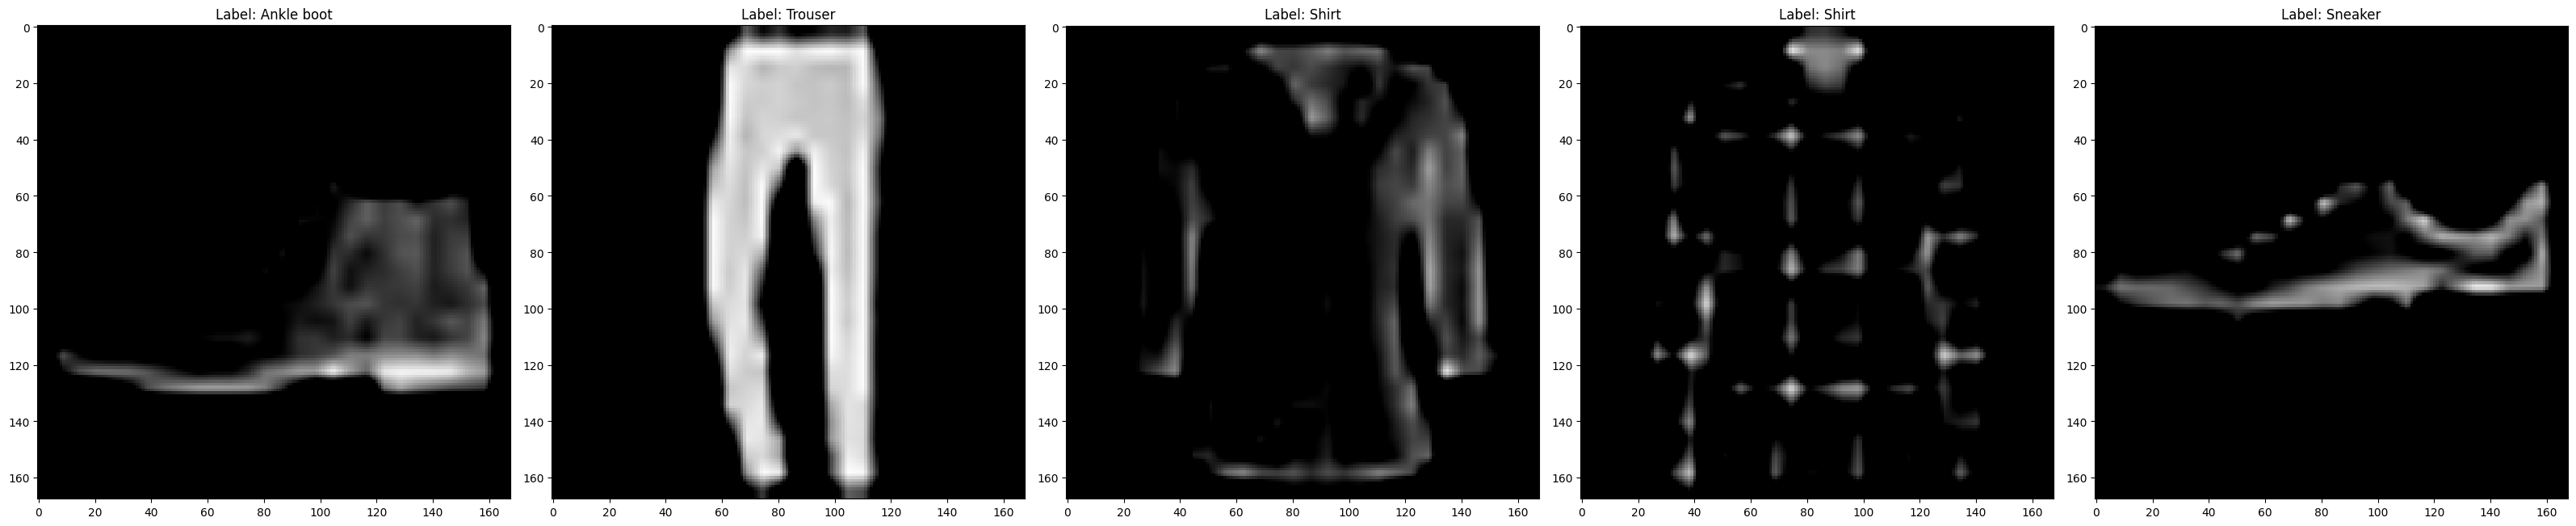

In [140]:
#### Print a few of the test data images

# Index of the images to plot (within the batch)
iix = [0,2,4,7,9]

#plt.figure(figsize=(8, 8))  # Set a larger figure size
plt.figure(figsize=(32, 32))

for i,ix in enumerate(iix):
    # Plot images
    plt.subplot(1,len(iix), i+1)
    plt.imshow(ex_images[ix])
    plt.title(f"Label: {class_names[ex_labels[ix]]}")

plt.tight_layout()
plt.show(out.astype('uint8'))

In [141]:
ex_images[0].shape  # Shows the shape of the image 56 x 56 and has three colours 

TensorShape([168, 168, 3])

In [160]:

##################### TODO: YOUR CODE STARTS HERE #####################
#### Read in the model to transfer
input_shape = ex_images[0].shape
tl_model = keras.applications.Xception(weights='imagenet',include_top=False, input_shape=input_shape)

# For now we are not training the parameters in the transfered model
tl_model.trainable = True
##################### TODO: YOUR CODE ENDS HERE #######################
tl_model.summary(show_trainable=True, line_length=100)

Model: "xception"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃       Param # ┃ Connected to         ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer_8            │ (None, 168, 168, 3)  │             0 │ -                    │    -    │
│ (InputLayer)             │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv1 (Conv2D)    │ (None, 83, 83, 32)   │           864 │ input_layer_8[0][0]  │    Y    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv1_bn          │ (None, 83, 83, 32)   │           128 │ block1_conv1[0][0]   │    Y    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv1_act         │ (None, 83, 83, 32)   │             0 │ block1_conv1_bn[0][… │    -    │
│ (Activation)             │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv2 (Conv2D)    │ (None, 81, 81, 64)   │        18,432 │ block1_conv1_act[0]… │    Y    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv2_bn          │ (None, 81, 81, 64)   │           256 │ block1_conv2[0][0]   │    Y    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv2_act         │ (None, 81, 81, 64)   │             0 │ block1_conv2_bn[0][… │    -    │
│ (Activation)             │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv1          │ (None, 81, 81, 128)  │         8,768 │ block1_conv2_act[0]… │    Y    │
│ (SeparableConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv1_bn       │ (None, 81, 81, 128)  │           512 │ block2_sepconv1[0][… │    Y    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv2_act      │ (None, 81, 81, 128)  │             0 │ block2_sepconv1_bn[… │    -    │
│ (Activation)             │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv2          │ (None, 81, 81, 128)  │        17,536 │ block2_sepconv2_act… │    Y    │
│ (SeparableConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv2_bn       │ (None, 81, 81, 128)  │           512 │ block2_sepconv2[0][… │    Y    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ conv2d_30 (Conv2D)       │ (None, 41, 41, 128)  │         8,192 │ block1_conv2_act[0]… │    Y    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_pool              │ (None, 41, 41, 128)  │          

 Total params: 20,861,480 (79.58 MB)

 Trainable params: 20,806,952 (79.37 MB)

 Non-trainable params: 54,528 (213.00 KB)

In [161]:
##################### TODO: CHANGE!
# name_of_last_TL_layer = 'block5_pool' # Runda 1 med default layers x = keras.layers.BatchNormalization(axis=-1)(x) och x = keras.layers.Flatten()(x) och batchsize 128
# name_of_last_TL_layer = 'block14_sepconv2_act'# Runda 2 # Jag la in hela min model inklusivt 2 Conv2D-lager och maxpooling lager och körde med batch size 128 Learning rate 1-e-4-1-e-5
# name_of_last_TL_layer ='batch_normalization_13' # Runda 3 Jag bytte till batch size 128 med 2 conv2d-lager
name_of_last_TL_layer ='block10_sepconv3_bn' # Runda 4 Jag behöll 2 conv2D lager, batchsize 352




In [162]:
#### Build our own layers on top of the transfered model (use a functional definition as this is easier)

# Step 1. Get an output tensor of the last transfer-model layer that we want to include
x = tl_model.get_layer(name_of_last_TL_layer).output

##################### TODO: YOUR CODE STARTS HERE #####################
# Step 2. Stack our own layers on top
# x = keras.layers.BatchNormalization(axis=-1)(x)
##### more layers
# x = keras.layers.Flatten()(x)
##### more layers
x = keras.layers.Conv2D(
        filters=256, 
        kernel_size=(3, 3), 
        padding='same', 
        activation='relu', 
        kernel_initializer='he_normal')(x) 
x = keras.layers.MaxPool2D(pool_size=3, strides=2, padding='same')(x)
# x = keras.layers.Conv2D(filters=256,kernel_size=(3, 3), padding='same', activation='relu', kernel_initializer='he_normal')(x) 
x = keras.layers.Conv2D(
        filters=256, 
        kernel_size=(3, 3), 
        padding='same', 
        activation='relu', 
        kernel_initializer='he_normal')(x) 
x = keras.layers.MaxPool2D(pool_size=3, strides=2,padding='same')(x) 
x = keras.layers.Flatten()(x)
x = keras.layers.Dense(units=32, activation='relu', kernel_initializer='he_normal')(x) 
x = keras.layers.BatchNormalization()(x)

##################### TODO: YOUR CODE ENDS HERE #######################
x = keras.layers.Dense(10, activation='softmax')(x)

# Creating new combined model. Note that this is NOT a Sequential() model.
model = keras.models.Model(inputs=tl_model.input, outputs=x)

print(model.summary(show_trainable=True, line_length=100))

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃       Param # ┃ Connected to         ┃ Traina… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ input_layer_8            │ (None, 168, 168, 3)  │             0 │ -                    │    -    │
│ (InputLayer)             │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv1 (Conv2D)    │ (None, 83, 83, 32)   │           864 │ input_layer_8[0][0]  │    Y    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv1_bn          │ (None, 83, 83, 32)   │           128 │ block1_conv1[0][0]   │    Y    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv1_act         │ (None, 83, 83, 32)   │             0 │ block1_conv1_bn[0][… │    -    │
│ (Activation)             │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv2 (Conv2D)    │ (None, 81, 81, 64)   │        18,432 │ block1_conv1_act[0]… │    Y    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv2_bn          │ (None, 81, 81, 64)   │           256 │ block1_conv2[0][0]   │    Y    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block1_conv2_act         │ (None, 81, 81, 64)   │             0 │ block1_conv2_bn[0][… │    -    │
│ (Activation)             │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv1          │ (None, 81, 81, 128)  │         8,768 │ block1_conv2_act[0]… │    Y    │
│ (SeparableConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv1_bn       │ (None, 81, 81, 128)  │           512 │ block2_sepconv1[0][… │    Y    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv2_act      │ (None, 81, 81, 128)  │             0 │ block2_sepconv1_bn[… │    -    │
│ (Activation)             │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv2          │ (None, 81, 81, 128)  │        17,536 │ block2_sepconv2_act… │    Y    │
│ (SeparableConv2D)        │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_sepconv2_bn       │ (None, 81, 81, 128)  │           512 │ block2_sepconv2[0][… │    Y    │
│ (BatchNormalization)     │                      │               │                      │         │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ conv2d_30 (Conv2D)       │ (None, 41, 41, 128)  │         8,192 │ block1_conv2_act[0]… │    Y    │
├──────────────────────────┼──────────────────────┼───────────────┼──────────────────────┼─────────┤
│ block2_pool              │ (None, 41, 41, 128)  │          

 Total params: 13,165,554 (50.22 MB)

 Trainable params: 13,132,418 (50.10 MB)

 Non-trainable params: 33,136 (129.44 KB)

None


In [163]:
#### Compile the model (note SparseCategoricalCrossentropy as we have not converted labels)
### We are continuing to use Adam optimization and not SGD as in the example on page 519.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4-1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")]
)

In [164]:
#### Training the model
# batch_size = 32 # Now set in datastream
epochs = 30

# Set callback functions to early stop training and save the best model so far
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=3,restore_best_weights = True)]

start = time.perf_counter()
history = model.fit(train_ds,
                    epochs=epochs,
                    shuffle=True,
                    verbose=1,
                    validation_data=val_ds,
                    callbacks=callbacks)
end = time.perf_counter()
print(f"Time to run: {end - start:.2f}s",)

Epoch 1/30


E0000 00:00:1764012722.252766     106 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1764012722.478581     106 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-11-24 19:32:04.223096: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng0{} for conv (f32[728,728,1,1]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,728,21,21]{3,2,1,0}, f32[128,728,21,21]{3,2,1,0}), window={size=1x1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardFilter", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2025-11-24 19:32:04.369291: E ext

375/375 ━━━━━━━━━━━━━━━━━━━━ 220s 487ms/step - acc: 0.8396 - loss: 0.5275 - val_acc: 0.9119 - val_loss: 0.3239
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 481ms/step - acc: 0.9533 - loss: 0.1712 - val_acc: 0.9256 - val_loss: 0.2664
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 481ms/step - acc: 0.9886 - loss: 0.0746 - val_acc: 0.9414 - val_loss: 0.2025
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 481ms/step - acc: 0.9983 - loss: 0.0311 - val_acc: 0.9413 - val_loss: 0.1985
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 481ms/step - acc: 0.9993 - loss: 0.0177 - val_acc: 0.9406 - val_loss: 0.2007
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 481ms/step - acc: 0.9999 - loss: 0.0099 - val_acc: 0.9430 - val_loss: 0.1920
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 481ms/step - acc: 1.0000 - loss: 0.0061 - val_acc: 0.9457 - val_loss: 0.1874
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 481ms/step - acc: 1.0000 - loss: 0.0043 - val_acc: 0.9463 - val_loss: 0.1871
Epoch 9/30
375/375 ━━━━━━━━━━━━━━━━

In [165]:
# Evaluate
test_loss, test_acc = model.evaluate(test_ds)
print(f'Test accuracy: {test_acc:.3f}')

78/78 ━━━━━━━━━━━━━━━━━━━━ 9s 121ms/step - acc: 0.9445 - loss: 0.1963
Test accuracy: 0.943


In [ ]:
### ANALYS
Runda 1: valde jag 28*3, name_of_last_TL_layer = 'block14_sepconv2_act', fick trainable params:5,342,122 . körtid: 707.10s. Testsnoggrannhet: 0.889

Runda 2:valde jag 28*3, name_of_last_TL_layer = 'batch_normalization_13', fick trainable params:2,982,826. körtid: s. Testsnoggrannhet: 0.926

Runda 3: 28*3 name_of_last_TL_layer ='block10_sepconv3_bn', fick trainable params: 2,341,802. körtid:s. Testsnoggrannhet:  0.921

Runda 4: 28*3 Nu öppnar jag upp hela Xception modellen och låter den träna, fick trainable params:13,132,418. körtid:2024.37s. Testsnoggrannhet: 0.943





## Analys

Utvärdera Xception och jämför med när du använde VGG16. 


### NEW STUDENTSVAR (VG Analys):
När hela Xception-modellen tränas tillsammans med den min model så växer prestandan från 92.1% till 94.3% %. Den körde på 13,132,418 parametrar och tog körtid: 2024.37s
VGG16 och min modell hade Trainable Params : 2,989,802. Körtid:1102.62s och test noggrannheten var 94.4%

Jag tycker att båda modellerna presterade lika bra i noggrannhet. Men VGG16 var snabbare och effektivare. 
Xception sägs kunna upnå 97% noggrannhet. Jag fick den inte upp dit. Jag tror det kan vara mitt val av model och vilka lager i Xception jag valde att avfryda innan jag tränade båda modellerna tillsammans. Xception är en betydligt större model än VGG16 och tar längre tid att träna. Jag blir lite osäker på om jag normalizerade bilderna korrekt. De ser så suddiga ut.



# För Alla Delar
Sammanställ dina resultat och gör en analys om hur de olika modellerna beter sig, speciellt mellan de modeller du har prövat i denna laboration, men även mot dina resultat i Laboration 1.

### NEW STUDENTSVAR (Analys):
När hela Xception-modellen tränas tillsammans med den min model så växer prestandan från 92.1% till 94.3% %. Den körde på 13,132,418 parametrar och tog körtid: 2024.37s VGG16 och min modell hade Trainable Params : 2,989,802. Körtid:1102.62s och test noggrannheten var 94.4%.
Min Sequential modell med färre antal lager presterade ändå rätt så bra med testnoggrannhet upp till 91.3% eller 92.9% särskilt med tuner av flera hyperparametrar. Men den tog sjukt lång tid (mellan 1 och 2 timmar) att hitta optimala hyperparametrarna.
VGG16 är nog bästa modellen.



# AI Deklaration
Användning av Al-verktyg är "tillåtet", men vi vill se kommentar i koden, där det har använts för att skapa hela block av kod.

Här på slutet ska du ange allmänt vilka AI-verktyg som använts, hur du använt dem, och hur användbara dessa verktyg är. Om du inte använt AI-stöd så skriv bara att "AI-verktyg har ej använts".

### STUDENTSVAR (AI-användning):
Jag använde AI för att hitta sätt att normalizera bilderna genom prompten : 
Normalise images to a float between -1 and 1 using this example : # Normalise images to a float between 0 and 1 train_images0 = train_images0.astype('float32') / 255 test_images = test_images.astype('float32') / 255

och fick då svaret: train_images0 = (train_images0 / 255.0) * 2.0 - 1.0
test_images = (test_images / 255.0) * 2.0 - 1.0

Jag försökte bekräfta att detta var rätt i boken men verkade inte hitta ett liknande exempel. Kanske letade jag inte på rätta sidor.